In [1]:
import os
import numpy as np
import zonist.data as zd
import anndata as ad

INFO:zonist.data:
Time: 20250107-17.33.52


In [2]:
import scanpy as sc
import squidpy as sq

In [3]:
import pandas as pd

In [4]:
from sklearn.utils import sparsefuncs


In [83]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

with object produced by `scripts/1-adata-pixel-selection.py` 

In [5]:
quantif_file = "whole-ellis_mx_f1.h5ad"

In [6]:
mydata_dir = "/home/johanna/spatial_thesis/spatial_metabolomics/data"
subdir = "whole-ellis"

In [7]:
anno_dict = {'HMDB': "whole-ellis_hmdb.csv",
             'LipidMaps': "whole-ellis_lipidmaps.csv"}

In [8]:
me_annots = zd.MetabolomeAnnotations(name="demo",
                            data_dir=mydata_dir,
                            subfolder=subdir,
                            annotation_files=anno_dict)
me_annots.load_annotation()

# 1.2) matrix of quantifications (==intensities)
print("Opening the quantifications")
adata = ad.read_h5ad(filename=os.path.join(
    mydata_dir, subdir, quantif_file))
bool_equal = np.all(np.array(
    sorted(me_annots.annotationtbl["mz"].unique())) == np.array(
    sorted(adata.var["var"].tolist())))
print(f"perfect match between mz in me_a.annotationtbl "
      f"and adata.X: {bool_equal}")

# 2) loading mappings data
# the files are provided and location is the one recommended (in data/)
me_refmap = zd.MetaboliteReferenceMappings(
    data_dir=mydata_dir,
    subfolder="metabolites-mappings",
    mapping_files={'HMDB': "HMDB-to-KEGG_05-07-24.tsv",
                   'LipidMaps': "LipidMaps-to-KEGG_10-18-24.tsv" }
)
me_refmap.load_mappings()
me_annots.convert_ids_to_kegg(me_refmap.table)

INFO:zonist.data:Loading annotations
INFO:zonist.data:  loading LipidMaps
INFO:zonist.data:  loading HMDB
Opening the quantifications
perfect match between mz in me_a.annotationtbl and adata.X: True
INFO:zonist.data:Loading reference files for mapping compounds identifiers
INFO:zonist.data:  loading LipidMaps
INFO:zonist.data: your loaded dataframe :
       LipidMaps    KEGG
0  LMFA08030003  C11839
1  LMFA08030004  C11841
INFO:zonist.data:  loading HMDB
INFO:zonist.data: your loaded dataframe :
           HMDB    KEGG
0  HMDB0000001  C01152
1  HMDB0000002  C00986
INFO:zonist.data:Translating ids in the metabolome annotation table, to KEGG


In [9]:
me_annots.annotationtbl.head()

,mz,formula,moleculeIds,moleculeNames,KEGG,database
15315,217.195077,C16H24,HMDB0036578,Cyperotundone,C17501,HMDB
10005,219.210727,C16H26,HMDB0034498,"(3E,7E)-4,8,12-Trimethyl-1,3,7,11-tridecatetraene",C20700,HMDB
14675,221.096091,C16H12O,HMDB0013139,1-Hydroxypyrene,C14519,HMDB
15160,223.074705,C7H14N2O4S,HMDB0000099,L-Cystathionine,C02291,HMDB
11873,223.075356,C15H10O2,HMDB0003075,Flavone,C15608,HMDB


In [10]:
len(me_annots.annotationtbl['KEGG'].unique())

1053

In [12]:
tdf = adata.var.copy()
tdf = tdf.sort_values(by="var", ascending=True)
tdf.tail()

,var,variance
1189.685703055,1189.685703,59.395210
1191.701353119,1191.701353,52.237869
1191.845241371,1191.845241,101.722137
1192.787620415,1192.787620,96.811729
1195.847550049,1195.847550,100.983261


In [13]:
mz_whom_mapkegg_in_data = set(
    list(me_annots.annotationtbl['mz'].unique())
).intersection(set(
    list(adata.var['var'])
))

In [85]:
len(mz_whom_mapkegg_in_data)

676

In [62]:
adata = adata[:, 
            list(adata.var.loc[adata.var[
                'var'].isin(list(mz_whom_mapkegg_in_data)), :].index)].copy()

In [63]:
adata

AnnData object with n_obs × n_vars = 133444 × 676
    obs: 'obs', 'spatial_domain'
    var: 'var', 'variance'
    uns: 'spatial', 'spatial_domain_colors'
    obsm: 'spatial'
    varm: 'metabolites'

In [88]:
Xraw_676features = adata.X.copy()

In [91]:
# as the features are few (m = 676) I run kmeans in all

In [90]:
sc.pp.log1p(adata)
sc.tl.pca(adata)

In [94]:
kmeans = KMeans(n_clusters=15, random_state=0).fit(adata.obsm['X_pca'])
adata.obs['kmeans15'] = kmeans.labels_.astype(str)

/home/johanna/micromamba/envs/prototype_py/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


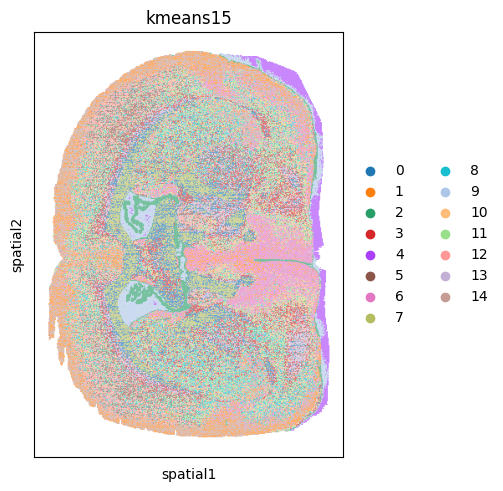

In [95]:
sq.pl.spatial_scatter(
    adata, color=["kmeans15"],
    img=False
)

In [98]:
kmeans = KMeans(n_clusters=11, random_state=0).fit(adata.obsm['X_pca'])
adata.obs['kmeans11'] = kmeans.labels_.astype(str)

/home/johanna/micromamba/envs/prototype_py/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


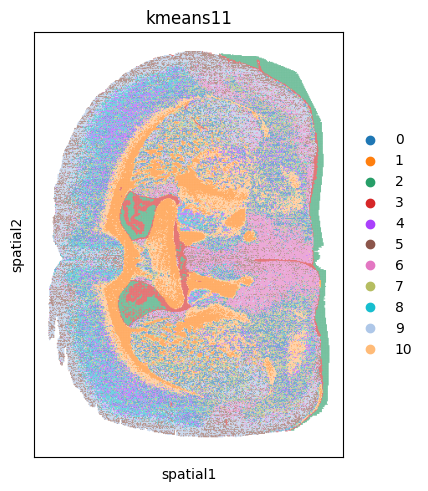

In [99]:
sq.pl.spatial_scatter(
    adata, color=["kmeans11"],
    img=False
)

In [ ]:
#######

<div class="alert alert-block alert-warning">
<b> Warning: </b>many different m/z features (and different formulas) can map to a given KEGG compound id!
</div>

It was verified manually that HMDB0004842, 44, 43 and 45, correspond all to C04730
And in an extreme case, there are 55 mz that map to the KEGG id C00157

**TODO**: think in a solution to diminish this ambiguities?, e.g. retain the mz that are relevants for clusters ?  or leave them to play all in the pathways ? 

In [ ]:
# Check the kegg id that appears 55 times because mapping to 55 different mz

In [66]:
df2 = me_annots.annotationtbl.groupby("KEGG", as_index=False).size()
df2.loc[df2['size'] >= 2,:].head(2)

,KEGG,size
7,C00157,55
8,C00165,13


In [67]:
the55times = me_annots.annotationtbl.loc[me_annots.annotationtbl[
"KEGG"] == df2.loc[df2['size'] == 55, "KEGG"].item(),:]

In [68]:
the55times['mz'].to_numpy()

array([704.52248176, 704.55886727, 716.55886727, 718.53813183,
       720.55378189, 724.49118163, 730.53813183, 730.57451733,
       734.56943196, 740.52248176, 740.55886727, 742.57451733,
       744.55378189, 744.5901674 , 746.56943196, 748.58508202,
       756.55378189, 758.56943196, 760.58508202, 762.60073208,
       768.55378189, 770.60581746, 780.55378189, 782.56943196,
       784.58508202, 786.60073208, 788.61638215, 790.57451733,
       790.63203221, 792.55378189, 806.56943196, 810.60073208,
       812.61638215, 814.63203221, 816.5901674 , 818.60581746,
       820.62146753, 830.66333234, 832.58508202, 832.6789824 ,
       834.60073208, 836.61638215, 842.66333234, 858.60073208,
       868.6789824 , 878.56943196, 880.58508202, 882.60073208,
       888.64768227, 896.71028253, 898.7259326 , 900.74158266,
       916.6789824 , 918.69463247, 920.71028253])

In [70]:
tiny = adata[:, 
            list(adata.var.loc[adata.var[
                'var'].isin(the55times['mz'].tolist()), :].index)]

In [87]:
tiny

AnnData object with n_obs × n_vars = 133444 × 55
    obs: 'obs', 'spatial_domain', 'kmeans5'
    var: 'var', 'variance'
    uns: 'spatial', 'spatial_domain_colors', 'log1p', 'pca', 'kmeans15_colors', 'kmeans5_colors'
    obsm: 'spatial', 'X_pca'
    varm: 'metabolites', 'PCs'

In [75]:
sc.pp.log1p(tiny)
sc.tl.pca(tiny)

/home/johanna/micromamba/envs/prototype_py/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:401: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [84]:
kmeans = KMeans(n_clusters=5, random_state=0).fit(tiny.obsm['X_pca']) 
tiny.obs['kmeans5'] = kmeans.labels_.astype(str)

/home/johanna/micromamba/envs/prototype_py/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [85]:
tiny

AnnData object with n_obs × n_vars = 133444 × 55
    obs: 'obs', 'spatial_domain', 'kmeans5'
    var: 'var', 'variance'
    uns: 'spatial', 'spatial_domain_colors', 'log1p', 'pca', 'kmeans15_colors'
    obsm: 'spatial', 'X_pca'
    varm: 'metabolites', 'PCs'

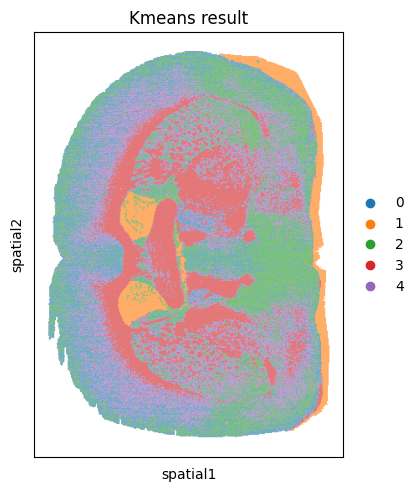

In [86]:
sq.pl.spatial_scatter(
    tiny, color=["kmeans5"],
    img=False, title="Kmeans result")

In [ ]:
##

In [72]:
tdf = adata.var.copy()
tdf = tdf.sort_values(by="var", ascending=True)

In [73]:
tdf.tail()

,var,variance
1164.834342339,1164.834342,185.497330
1165.720434783,1165.720435,67.531693
1171.694613959,1171.694614,73.641670
1177.829591307,1177.829591,81.722107
1181.751734911,1181.751735,64.190857


In [64]:
adata

View of AnnData object with n_obs × n_vars = 133444 × 676
    obs: 'obs', 'spatial_domain'
    var: 'var', 'variance'
    uns: 'spatial', 'spatial_domain_colors'
    obsm: 'spatial'
    varm: 'metabolites'